#  Customer Churn / Sales Trend Analysis

## 1. The business question
A manager wants to know:
1. Which **months** and **categories** earn the most revenue?
2. Who are our **best customers**, and how concentrated is our revenue?
3. Which customers have **stopped buying** (churn risk)?
4. What should we **do next**?



In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

sns.set_theme(style="whitegrid", palette="colorblind")

## 2. Create the data


In [2]:
rng = np.random.default_rng(2025)
n = 2000

# Uneven customer activity: a few heavy buyers, many occasional ones
activity = rng.gamma(0.8, 1.0, 300)
customer_p = activity / activity.sum()

orders = pd.DataFrame({
    "order_id": np.arange(1, n + 1),
    "order_date": pd.Timestamp("2025-01-01") + pd.to_timedelta(rng.integers(0, 365, n), unit="D"),
    "customer_id": rng.choice(np.arange(1, 301), n, p=customer_p),
    "category": rng.choice(["Electronics", "Fashion", "Home", "Books"], n, p=[0.30, 0.35, 0.20, 0.15]),
    "amount": rng.gamma(2.0, 600, n),
})

season = {11: 1.3, 12: 1.5}
orders["amount"] = (orders["amount"] * orders["order_date"].dt.month.map(season).fillna(1.0)).round(2)
orders.head()

,order_id,order_date,customer_id,category,amount
0,1,2025-10-04,226,Fashion,239.76
1,2,2025-08-30,179,Home,380.07
2,3,2025-04-12,176,Fashion,1242.26
3,4,2025-04-25,35,Home,3245.47
4,5,2025-08-31,14,Electronics,1821.24


## 3. Check the data

In [3]:
print("Shape:", orders.shape)
print("Missing values:", orders.isna().sum().sum())
print("Duplicate orders:", orders.duplicated(subset="order_id").sum())
print("Date range:", orders["order_date"].min().date(), "to", orders["order_date"].max().date())
orders.dtypes

Shape: (2000, 5)
Missing values: 0
Duplicate orders: 0
Date range: 2025-01-01 to 2025-12-31


,0
order_id,int64
order_date,datetime64[ns]
customer_id,int64
category,object
amount,float64


## 4. Feature engineering: date features
From the order date I create month, month name, quarter and weekday columns.

In [4]:
orders["month"] = orders["order_date"].dt.to_period("M")
orders["quarter"] = orders["order_date"].dt.quarter
orders["weekday"] = orders["order_date"].dt.day_name()
orders[["order_date", "month", "quarter", "weekday"]].head()

,order_date,month,quarter,weekday
0,2025-10-04,2025-10,4,Saturday
1,2025-08-30,2025-08,3,Saturday
2,2025-04-12,2025-04,2,Saturday
3,2025-04-25,2025-04,2,Friday
4,2025-08-31,2025-08,3,Sunday


## 5. Revenue trend by month

In [5]:
monthly = orders.groupby("month")["amount"].sum()
growth = (monthly.pct_change() * 100).round(1)

trend = pd.DataFrame({"revenue": monthly.round(0), "growth_%": growth})
trend

,revenue,growth_%
month,,
2025-01,216624.0,NaN
2025-02,180538.0,-16.7
2025-03,190390.0,5.5
2025-04,179249.0,-5.9
2025-05,249903.0,39.4
2025-06,220419.0,-11.8
2025-07,206969.0,-6.1
2025-08,220295.0,6.4
2025-09,207242.0,-5.9


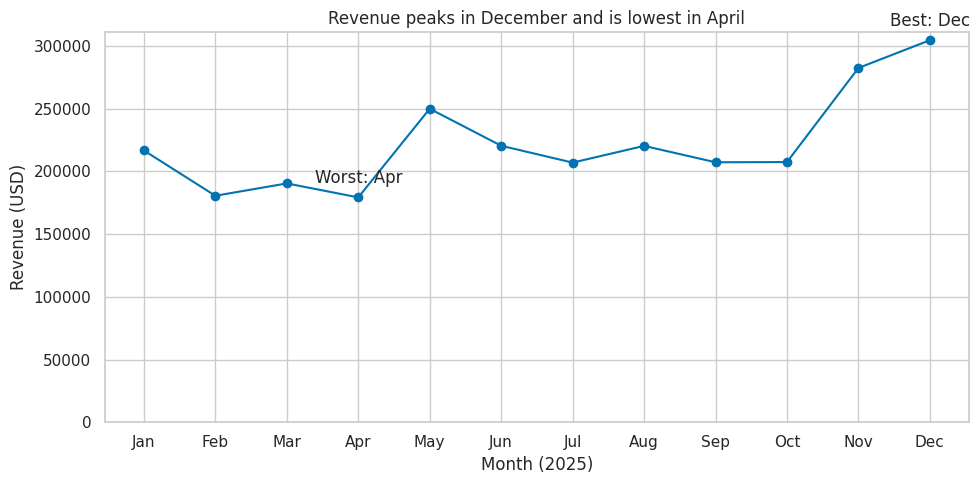

Takeaway: December earned $304,553, which is 1.7x the weakest month (April, $179,249).


In [6]:
best_m, worst_m = monthly.idxmax(), monthly.idxmin()
x = list(range(len(monthly)))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x, monthly.values, marker="o")
ax.set_xticks(x)
ax.set_xticklabels([p.strftime("%b") for p in monthly.index])
ax.set_ylim(0, None)
ax.annotate(f"Best: {best_m.strftime('%b')}", (x[list(monthly.index).index(best_m)], monthly.max()),
            textcoords="offset points", xytext=(0, 10), ha="center")
ax.annotate(f"Worst: {worst_m.strftime('%b')}", (x[list(monthly.index).index(worst_m)], monthly.min()),
            textcoords="offset points", xytext=(0, 10), ha="center")
ax.set(title=f"Revenue peaks in {best_m.strftime('%B')} and is lowest in {worst_m.strftime('%B')}",
       xlabel="Month (2025)", ylabel="Revenue (USD)")
plt.tight_layout()
plt.show()

print(f"Takeaway: {best_m.strftime('%B')} earned ${monthly.max():,.0f}, which is "
      f"{monthly.max() / monthly.min():.1f}x the weakest month ({worst_m.strftime('%B')}, ${monthly.min():,.0f}).")

## 6. Compare categories

In [7]:
by_cat = (orders.groupby("category")["amount"]
                .agg(["sum", "mean", "count"])
                .sort_values("sum", ascending=False)
                .round(1))
by_cat["share_%"] = (by_cat["sum"] / by_cat["sum"].sum() * 100).round(1)
by_cat

,sum,mean,count,share_%
category,,,,
Fashion,940391.8,1347.3,698,35.3
Electronics,779489.6,1334.7,584,29.2
Home,547971.5,1356.4,404,20.6
Books,398129.3,1267.9,314,14.9


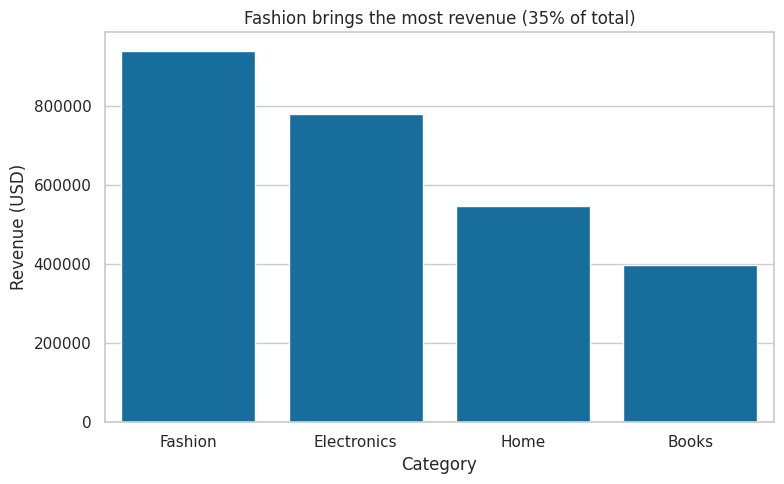

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=by_cat.index, y=by_cat["sum"], ax=ax)
ax.set(title=f"{by_cat.index[0]} brings the most revenue ({by_cat['share_%'].iloc[0]:.0f}% of total)",
       xlabel="Category", ylabel="Revenue (USD)", ylim=(0, None))
plt.tight_layout()
plt.show()

### Pivot table: month by category

In [9]:
pivot = orders.pivot_table(values="amount", index="month", columns="category",
                           aggfunc="sum", fill_value=0).round(0)
pivot

category,Books,Electronics,Fashion,Home
month,,,,
2025-01,29618.0,79631.0,79428.0,27948.0
2025-02,21240.0,57231.0,75441.0,26626.0
2025-03,29110.0,57996.0,61195.0,42090.0
2025-04,47180.0,33831.0,61103.0,37134.0
2025-05,32872.0,70928.0,110389.0,35713.0
2025-06,45355.0,54422.0,68568.0,52074.0
2025-07,26528.0,58945.0,72786.0,48709.0
2025-08,30153.0,66767.0,68338.0,55036.0
2025-09,19734.0,70154.0,85178.0,32176.0


In [10]:
weekday_rev = (orders.groupby("weekday")["amount"].sum()
                     .reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]))
q_rev = orders.groupby("quarter")["amount"].sum()

print("Revenue by weekday (USD):")
print(weekday_rev.round(0).to_string())
print()
print("Revenue by quarter (USD):")
print(q_rev.round(0).to_string())

Revenue by weekday (USD):
weekday
Monday       385533.0
Tuesday      395206.0
Wednesday    376730.0
Thursday     331865.0
Friday       398752.0
Saturday     387682.0
Sunday       390214.0

Revenue by quarter (USD):
quarter
1    587553.0
2    649571.0
3    634505.0
4    794353.0


## 7. Best customers: the 80/20 (Pareto) test

In [11]:
spend = orders.groupby("customer_id")["amount"].sum().sort_values(ascending=False)
n_cust = len(spend)

top10_n = max(n_cust // 10, 1)
top20_n = max(n_cust // 5, 1)
top10_share = spend.head(top10_n).sum() / spend.sum()
top20_share = spend.head(top20_n).sum() / spend.sum()

print(f"Customers who ordered: {n_cust}")
print(f"Top 10% of customers ({top10_n}) bring {top10_share:.0%} of revenue")
print(f"Top 20% of customers ({top20_n}) bring {top20_share:.0%} of revenue")

Customers who ordered: 241
Top 10% of customers (24) bring 33% of revenue
Top 20% of customers (48) bring 52% of revenue


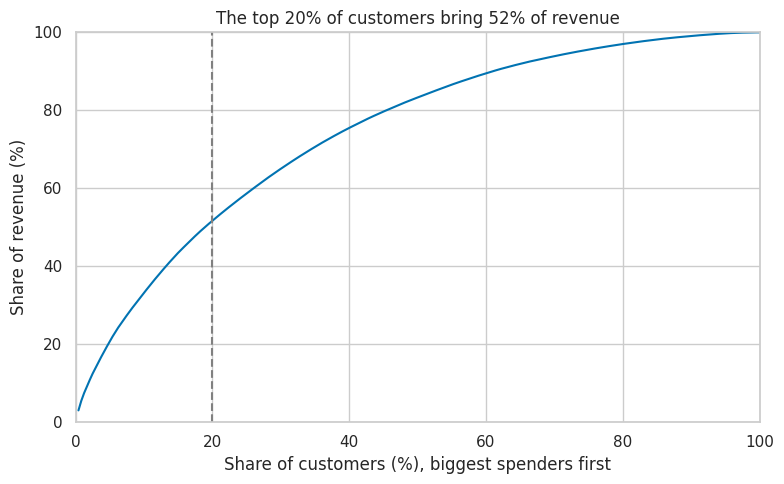

In [12]:
cum = spend.cumsum() / spend.sum() * 100
pct_cust = np.arange(1, n_cust + 1) / n_cust * 100

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pct_cust, cum.values)
ax.axvline(20, linestyle="--", color="grey")
ax.set(title=f"The top 20% of customers bring {top20_share:.0%} of revenue",
       xlabel="Share of customers (%), biggest spenders first", ylabel="Share of revenue (%)",
       xlim=(0, 100), ylim=(0, 100))
plt.tight_layout()
plt.show()

## 8. Churn risk


In [13]:
snapshot = orders["order_date"].max() + pd.Timedelta(days=1)
days_since = (snapshot - orders.groupby("customer_id")["order_date"].max()).dt.days
churned = days_since > 90

churn_rate = churned.mean()
churn_rev_share = spend[churned.reindex(spend.index)].sum() / spend.sum()
avg_churned = spend[churned.reindex(spend.index)].mean()

print(f"Customers inactive for more than 90 days: {int(churned.sum())} of {n_cust} ({churn_rate:.0%})")
print(f"These inactive customers spent ${avg_churned:,.0f} each on average and account for {churn_rev_share:.0%} of total revenue so far")

Customers inactive for more than 90 days: 64 of 241 (27%)
These inactive customers spent $3,881 each on average and account for 9% of total revenue so far


## 9. Recommendations (each backed by a number)

In [14]:
total = spend.sum()
avg_top = spend.head(top10_n).mean()
avg_rest = spend.iloc[top10_n:].mean()
best_cat, best_cat_share = by_cat.index[0], by_cat["share_%"].iloc[0]
q4_share = q_rev.loc[4] / q_rev.sum()

rec1 = (f"Run a loyalty programme for the top 10% of customers ({top10_n} people). They bring "
        f"{top10_share:.0%} of revenue and spend ${avg_top:,.0f} each on average versus ${avg_rest:,.0f} for everyone else.")
rec2 = (f"Launch a win-back campaign for the {int(churned.sum())} customers ({churn_rate:.0%}) who have not ordered in 90+ days. "
        f"They spent ${avg_churned:,.0f} each on average and made up {churn_rev_share:.0%} of revenue, so recovering them protects real income.")
rec3 = (f"Plan stock and marketing around the festive peak: {best_m.strftime('%B')} earns ${monthly.max():,.0f} "
        f"({monthly.max() / monthly.min():.1f}x {worst_m.strftime('%B')}), and Q4 gives {q4_share:.0%} of annual revenue. "
        f"Use promotions in {worst_m.strftime('%B')} to lift the weakest month, and keep {best_cat} "
        f"({best_cat_share:.0f}% of revenue) well stocked.")

for i, r in enumerate([rec1, rec2, rec3], 1):
    print(f"{i}. {r}\n")

1. Run a loyalty programme for the top 10% of customers (24 people). They bring 33% of revenue and spend $36,773 each on average versus $8,219 for everyone else.

2. Launch a win-back campaign for the 64 customers (27%) who have not ordered in 90+ days. They spent $3,881 each on average and made up 9% of revenue, so recovering them protects real income.

3. Plan stock and marketing around the festive peak: December earns $304,553 (1.7x April), and Q4 gives 30% of annual revenue. Use promotions in April to lift the weakest month, and keep Fashion (35% of revenue) well stocked.



## 10. One-page business brief
This cell writes `business_brief.md` using the numbers above, in the format Context, Key findings, Recommendations, Next steps.

In [15]:
brief = f"""# Sales Trend and Customer Analysis: Business Brief

**Prepared by:** Vansh Gupta, Data Science & AI Intern (InternCircle)

## Context
We analysed {len(orders):,} e-commerce orders from {n_cust} customers during 2025 (total revenue ${total:,.0f}) to see which months and categories earn most, who our best customers are, and who may be leaving. The data is **simulated**, so figures show the method and not a real business.

## Key findings
- **Seasonality:** {best_m.strftime('%B')} is the best month (${monthly.max():,.0f}) and {worst_m.strftime('%B')} the weakest (${monthly.min():,.0f}). Q4 brings {q4_share:.0%} of annual revenue.
- **Categories:** {best_cat} leads with {best_cat_share:.0f}% of revenue.
- **Concentration:** the top 10% of customers bring {top10_share:.0%} of revenue and the top 20% bring {top20_share:.0%}.
- **Churn risk:** {int(churned.sum())} customers ({churn_rate:.0%}) have not ordered in 90+ days; they made up {churn_rev_share:.0%} of revenue.

## Recommendations
1. {rec1}
2. {rec2}
3. {rec3}

## Next steps
- Replace the simulated data with real order data (with permission) and re-run the notebook.
- Test the loyalty and win-back offers on a small group first and compare results with a control group.
- Review the 90-day churn rule with the business, since the right window depends on how often customers normally buy.
"""

Path("business_brief.md").write_text(brief)
print(brief)

# Sales Trend and Customer Analysis: Business Brief

**Prepared by:** Vansh Gupta, Data Science & AI Intern (InternCircle)

## Context
We analysed 2,000 e-commerce orders from 241 customers during 2025 (total revenue $2,665,982) to see which months and categories earn most, who our best customers are, and who may be leaving. The data is **simulated**, so figures show the method and not a real business.

## Key findings
- **Seasonality:** December is the best month ($304,553) and April the weakest ($179,249). Q4 brings 30% of annual revenue.
- **Categories:** Fashion leads with 35% of revenue.
- **Concentration:** the top 10% of customers bring 33% of revenue and the top 20% bring 52%.
- **Churn risk:** 64 customers (27%) have not ordered in 90+ days; they made up 9% of revenue.

## Recommendations
1. Run a loyalty programme for the top 10% of customers (24 people). They bring 33% of revenue and spend $36,773 each on average versus $8,219 for everyone else.
2. Launch a win-back campaign

## 11. Limitations
- The data is simulated, so seasonality and customer behaviour reflect my assumptions and not a real business.
- The 90-day churn rule is a simple definition; customers near the end of the data may simply be between orders.
- Revenue patterns show association only; they do not prove why customers behave as they do.

In [16]:
note = (
    f"I used a generated (simulated) e-commerce dataset of {len(orders):,} orders from {n_cust} customers, so no real "
    f"customer data was used. I created month, quarter and weekday features, analysed monthly revenue and growth "
    f"(best month {best_m.strftime('%B')}, weakest {worst_m.strftime('%B')}), compared categories with groupby and a "
    f"month-by-category pivot table, and tested the 80/20 idea: the top 10% of customers bring {top10_share:.0%} of "
    f"revenue. Using a 90-day inactivity rule, {churn_rate:.0%} of customers are at risk of churning. I give three "
    f"recommendations backed by these numbers (loyalty offer, win-back campaign, festive-season planning) and a "
    f"one-page business brief (business_brief.md). Assumptions are stated in the notebook."
)
print(note)

I used a generated (simulated) e-commerce dataset of 2,000 orders from 241 customers, so no real customer data was used. I created month, quarter and weekday features, analysed monthly revenue and growth (best month December, weakest April), compared categories with groupby and a month-by-category pivot table, and tested the 80/20 idea: the top 10% of customers bring 33% of revenue. Using a 90-day inactivity rule, 27% of customers are at risk of churning. I give three recommendations backed by these numbers (loyalty offer, win-back campaign, festive-season planning) and a one-page business brief (business_brief.md). Assumptions are stated in the notebook.
